In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.titlesize'] = 12

CSV_PATH = Path('trajectory.csv')

if not CSV_PATH.exists():
    candidates = list(Path.cwd().rglob('trajectory.csv'))
    if len(candidates) == 1:
        CSV_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            'Не найден trajectory.csv. Положите notebook рядом с CSV '
            'или задайте полный путь в CSV_PATH.'
        )

df = pd.read_csv(CSV_PATH)
required = {'t', 'x', 'y', 'psi_tractor', 'psi_trailer', 'vx', 'vy', 'r1', 'r2', 'delta'}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f'В CSV отсутствуют колонки: {sorted(missing)}')

df['articulation'] = df['psi_tractor'] - df['psi_trailer']
df['sideslip'] = np.arctan2(df['vy'], df['vx'])

print(f'Файл: {CSV_PATH.resolve()}')
print(f'Строк: {len(df)}, интервал: {df.t.iloc[0]:.3f} ... {df.t.iloc[-1]:.3f} с')
df.head()

Файл: /Users/leryamerlen/Desktop/Diplomchik/truck_model_cpp/trajectory.csv
Строк: 26, интервал: 0.000 ... 5.000 с


,t,x,y,psi_tractor,psi_trailer,vx,vy,r1,r2,delta,steering_rate,longitudinal_acceleration,articulation,sideslip
0,0.0,0.000000,0.000000,0.000000,-0.080000,15.000000,1.000000,0.100000,-0.100000,0.000000,-0.011067,-0.010007,0.080000,0.066568
1,0.2,2.999375,0.158336,0.015010,-0.085968,15.007220,0.412732,0.049624,0.047748,-0.005946,-0.029830,0.093278,0.100978,0.027495
2,0.4,5.999535,0.268192,0.020456,-0.061832,15.002264,0.165335,0.010302,0.161286,-0.009080,0.008757,0.057016,0.082288,0.011020
3,0.6,8.997150,0.350747,0.020972,-0.031977,14.982721,0.048742,-0.002790,0.128093,-0.007201,0.020266,0.056145,0.052949,0.003253
4,0.8,11.991529,0.416933,0.019980,-0.011310,14.965968,0.007279,-0.005887,0.080256,-0.002977,0.016894,0.103565,0.031290,0.000486


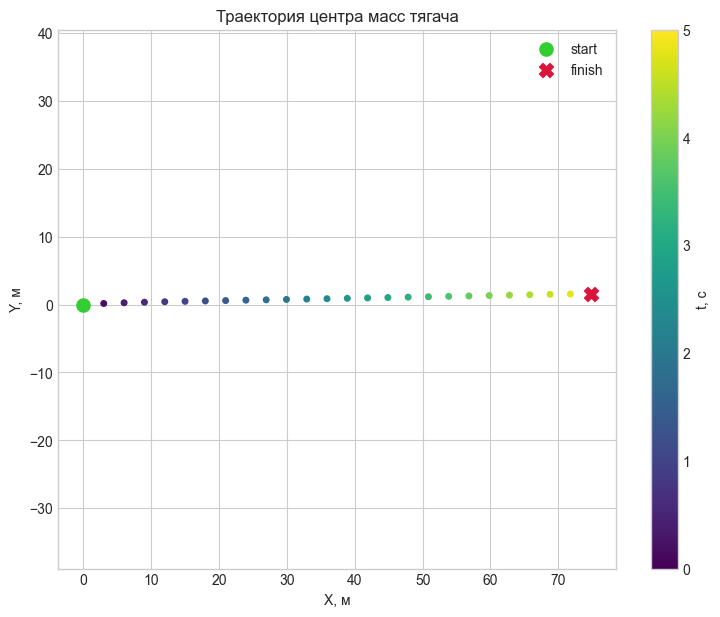

In [2]:
fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(df['x'], df['y'], c=df['t'], cmap='viridis', s=16)
ax.scatter(df['x'].iloc[0], df['y'].iloc[0], color='limegreen', s=90, marker='o', label='start', zorder=3)
ax.scatter(df['x'].iloc[-1], df['y'].iloc[-1], color='crimson', s=100, marker='X', label='finish', zorder=3)
ax.set_title('Траектория центра масс тягача')
ax.set_xlabel('X, м')
ax.set_ylabel('Y, м')
ax.axis('equal')
ax.legend()
fig.colorbar(points, ax=ax, label='t, с')
plt.show()

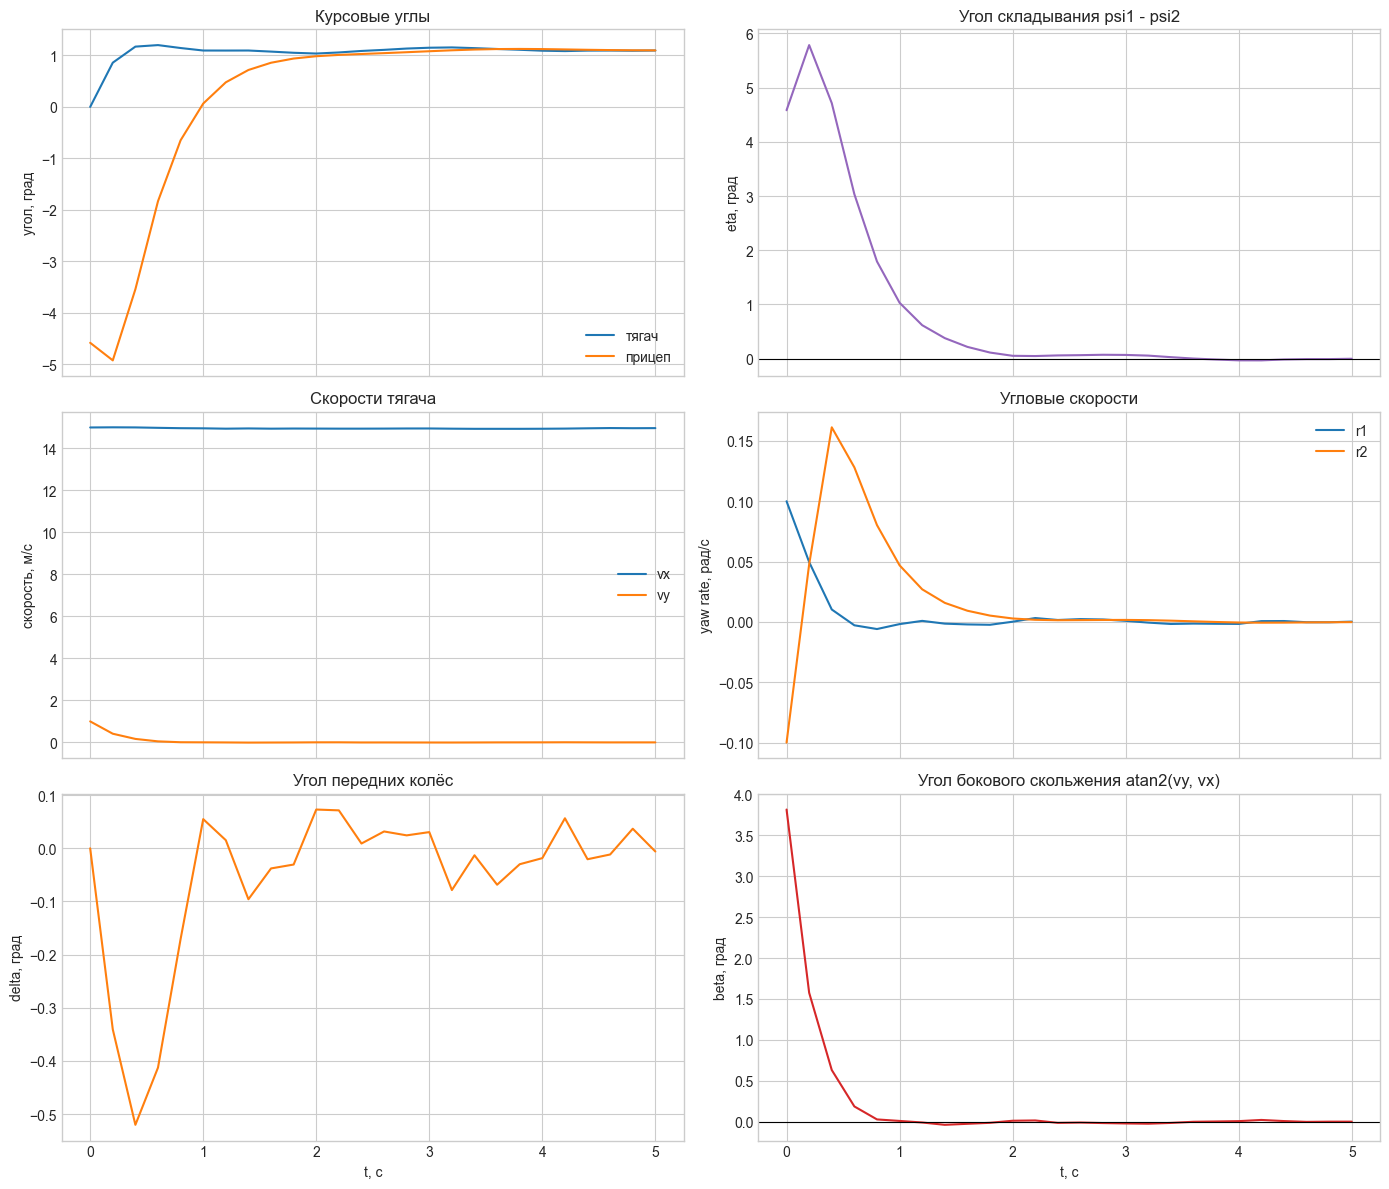

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)

axes[0, 0].plot(df.t, np.rad2deg(df.psi_tractor), label='тягач')
axes[0, 0].plot(df.t, np.rad2deg(df.psi_trailer), label='прицеп')
axes[0, 0].set_ylabel('угол, град')
axes[0, 0].set_title('Курсовые углы')
axes[0, 0].legend()

axes[0, 1].plot(df.t, np.rad2deg(df.articulation), color='tab:purple')
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set_ylabel('eta, град')
axes[0, 1].set_title('Угол складывания psi1 - psi2')

axes[1, 0].plot(df.t, df.vx, label='vx')
axes[1, 0].plot(df.t, df.vy, label='vy')
axes[1, 0].set_ylabel('скорость, м/с')
axes[1, 0].set_title('Скорости тягача')
axes[1, 0].legend()

axes[1, 1].plot(df.t, df.r1, label='r1')
axes[1, 1].plot(df.t, df.r2, label='r2')
axes[1, 1].set_ylabel('yaw rate, рад/с')
axes[1, 1].set_title('Угловые скорости')
axes[1, 1].legend()

axes[2, 0].plot(df.t, np.rad2deg(df.delta), color='tab:orange')
axes[2, 0].set_ylabel('delta, град')
axes[2, 0].set_title('Угол передних колёс')
axes[2, 0].set_xlabel('t, с')

axes[2, 1].plot(df.t, np.rad2deg(df.sideslip), color='tab:red')
axes[2, 1].axhline(0, color='black', linewidth=0.8)
axes[2, 1].set_ylabel('beta, град')
axes[2, 1].set_title('Угол бокового скольжения atan2(vy, vx)')
axes[2, 1].set_xlabel('t, с')

fig.tight_layout()
plt.show()

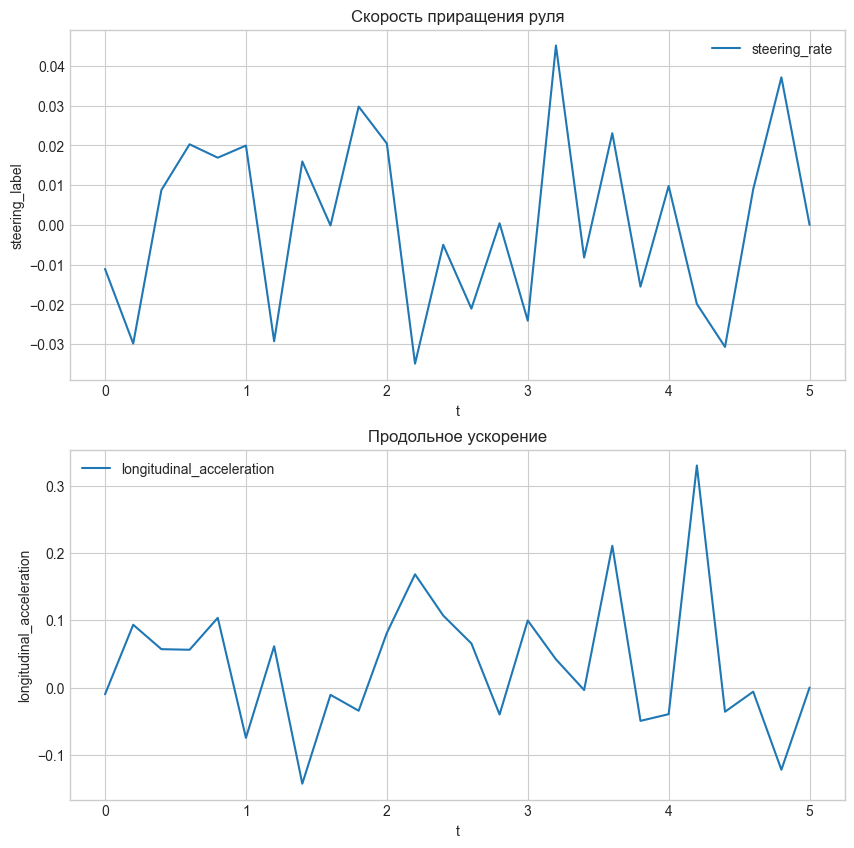

In [4]:
fix, axes = plt.subplots(2, 1,figsize=(10, 10))

axes[0].plot(df.t, df.steering_rate, label='steering_rate')
axes[0].set_ylabel('steering_label')
axes[0].legend()
axes[0].set_xlabel('t')
axes[0].set_title('Скорость приращения руля')
axes[1].plot(df.t, df.longitudinal_acceleration, label='longitudinal_acceleration')
axes[1].set_ylabel('longitudinal_acceleration')
axes[1].legend()
axes[1].set_xlabel('t')
axes[1].set_title('Продольное ускорение')

plt.show()

In [ ]:

articulation = df['psi_tractor'] - df['psi_trailer']
sideslip = np.arctan2(df['vy'], df['vx'])
yaw_rate_error = df['r1']                 # желаемый yaw rate = 0
yaw_rate_difference = df['r1'] - df['r2']

psi0 = df['psi_tractor'].iloc[0]
dx = df['x'] - df['x'].iloc[0]
dy = df['y'] - df['y'].iloc[0]
lateral_deviation = -np.sin(psi0) * dx + np.cos(psi0) * dy

rms = lambda x: np.sqrt(np.mean(np.asarray(x) ** 2))

metrics = pd.Series({
    'Max articulation, deg':
        np.rad2deg(np.abs(articulation).max()),

    'RMS articulation, deg':
        np.rad2deg(rms(articulation)),

    'Max sideslip, deg':
        np.rad2deg(np.abs(sideslip).max()),

    'RMS sideslip, deg':
        np.rad2deg(rms(sideslip)),

    'RMS tractor yaw rate, rad/s':
        rms(yaw_rate_error),

    'Max tractor yaw rate, rad/s':
        np.abs(yaw_rate_error).max(),

    'RMS yaw-rate difference, rad/s':
        rms(yaw_rate_difference),

    'Max lateral deviation, m':
        np.abs(lateral_deviation).max(),
})

display(metrics.to_frame('value').round(4))

,value
"Max articulation, deg",5.7856
"RMS articulation, deg",1.8688
"Max sideslip, deg",3.8141
"RMS sideslip, deg",0.8197
"RMS tractor yaw rate, rad/s",0.0221
"Max tractor yaw rate, rad/s",0.1000
"RMS yaw-rate difference, rad/s",0.0591
"Max lateral deviation, m",1.6175
